# 3. Routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/03_routing.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/03_routing.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You find routes on the turn graph of Monaco: between two roads, between two points, across modes, and with networkx and rustworkx.

| Call | Gives |
|---|---|
| `net.driving.route(a, b)` | the fastest route: `a`, `b` are edge ids or `(lon, lat)` points |
| `net.driving.directions(route)` | the turn-by-turn steps of a route |
| `net.route_multimodal_points(a, b)` | a route that walks and drives |
| `net.driving.to_networkx()`, `net.driving.to_rustworkx()` | the turn graph as a graph object |

Each call is a function of `duckosm.routing` or `duckosm.ml`: `net.driving.route(a, b)` is `duckosm.routing.route(net.driving, a, b)`.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,graph]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Build Monaco with three modes and the multimodal graph

The multimodal graph (`mm.*`) connects the modes at shared junctions. Only a config file turns it on.

In [2]:
area = duckosm.get("Monaco", out="data")    # the OSM file of Monaco and its boundary
config = f"""name: monaco
output_path: data/monaco_mm.duckdb
source: {{type: pbf, pbf_path: {area.pbf}}}
boundary: {{path: {area.boundary}}}
modes: [driving, walking, cycling]
multimodal: {{enabled: true}}
"""                                          # a config file: three modes and the multimodal graph
open("monaco.yaml", "w").write(config)      # write it
net = duckosm.build(config="monaco.yaml")   # build from the config file
net                                         # the card

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco_mm.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0
cycling,11305,4650,250.0,35.5


## Between two roads

A route goes from one edge to another edge. It obeys the turn restrictions of OSM.

In [3]:
q = "SELECT min(edge_id) AS edge_id FROM driving.edges WHERE name = ?"
start = int(net.sql(q, ["Boulevard du Larvotto"]).edge_id[0])    # one edge of Boulevard du Larvotto
end = int(net.sql(q, ["Avenue Princesse Grace"]).edge_id[0])     # one edge of Avenue Princesse Grace
r = net.driving.route(start, end)                                # the fastest route from edge to edge
round(r["time_s"]), round(r["length_m"]), len(r["edges"])        # seconds, metres, number of edges

(114, 1513, 29)

## Between two points

The points are (lon, lat). The route starts and ends at the nearest road, and adds the walk to it. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

In [4]:
a, b = (7.4155, 43.7285), (7.4335, 43.7468)    # Fontvieille and Larvotto
drive = net.driving.route(a, b)                # by car
walk = net.walking.route(a, b)                 # on foot
round(drive["time_s"] / 60, 1), round(walk["time_s"] / 60, 1)    # the two times in minutes

(3.8, 36.4)

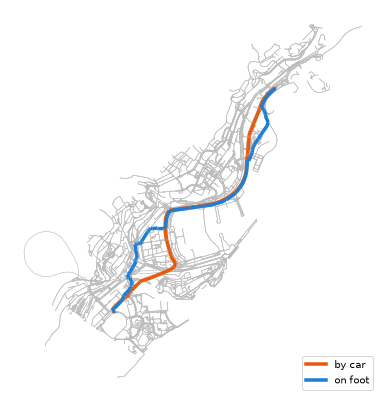

In [5]:
net.map(routes={"by car": drive, "on foot": walk})    # the two routes as lines on the map

## Turn-by-turn steps

In [6]:
[step["text"] for step in net.driving.directions(drive)]    # one step for each turn of the car route

['Head northwest on Avenue des Castelans',
 'At the roundabout, take the 1st exit onto Avenue Albert II',
 'At the roundabout, take the 3rd exit onto Avenue Albert II',
 'Continue onto Tunnel Rocher Palais',
 'Continue onto Tunnel Rocher Albert Ier',
 'Continue onto Tunnel Rocher Palais',
 'Continue onto Boulevard Albert 1er',
 'At the roundabout, take the 1st exit onto Avenue John F. Kennedy',
 'Continue onto Boulevard Louis II',
 'At the roundabout, take the 2nd exit onto Avenue Princesse Grace',
 'Arrive at your destination']

## Across modes

The route can walk to a car and drive. Each leg has its mode.

In [7]:
m = net.route_multimodal_points(a, b)                                        # the fastest route with any of the modes
[(leg["mode"], len(leg["edges"]), round(leg["time_s"])) for leg in m["legs"]]    # mode, edges and seconds of each leg

[('walking', 1, 3), ('driving', 75, 220), ('walking', 1, 0)]

## As a graph

A node is an `edge_id`. An arc is a legal turn. The weight of an arc is the time in seconds of the edge before the turn, so the graph time does not include the last edge.

In [8]:
import networkx as nx

g = net.driving.to_networkx()                                      # the turn graph of the driving network
nx.shortest_path(g, start, end, weight="weight") == r["edges"]     # the same path as the route

True

In [9]:
import rustworkx as rx

h = net.driving.to_rustworkx()                                     # the same graph in rustworkx
ix = h.attrs["index"]                                              # the node index of each edge_id
round(rx.dijkstra_shortest_path_lengths(h, ix[start], edge_cost_fn=float, goal=ix[end])[ix[end]], 1)    # the shortest time in seconds

113.2